# FER2013 — kiểm tra độ phân giải, classifier pretrained và hiệu chỉnh theo cặp

Run global-only 112×112 trước đạt best Val Acc 63.71%, Macro F1 60.17%,
clean train cuối 93.36%. Bước tiếp theo là thử riêng độ phân giải và classifier,
không tự tăng learning rate/epoch hay bật lại nhánh cặp để bù baseline yếu.

**Mặc định `global_ce_224`:** chỉ đổi ảnh lên **224×224**, giữ classifier
Linear 576→7, MixUp probability 0.3, không pair correction/class balancing.
Tổng vẫn **931.047 tham số**, nhưng tính toán nhiều hơn input 112.

Các preset riêng để thử:

- 112×112 với lớp ẩn **576→1024 pretrained + Hardswish → Dropout → Linear 1024→7**.
- Kết hợp ảnh 224 và classifier có lớp ẩn, sau khi xem các thử nghiệm riêng.
- Tăng riêng MixUp probability từ 0.3 lên 0.5, alpha vẫn 0.1.
- Giữ các preset global/pair/loss/gate cũ để đối chứng khi baseline phù hợp.

Head có lớp ẩn giữ lại weights ImageNet của Linear 576→1024, chỉ thay lớp
phân loại cuối. Global-only có **1.525.031 tham số**, model 3 cặp có **1.527.789**.
Pretrained hidden layer được fine-tune bằng backbone LR, các lớp mới bằng head LR.

Vẫn pilot 15 + main 35 epoch, backbone LR 1e-4, split seed 42, một GPU mặc định.
Thanh tiến độ text để tránh lỗi widget. Cache RAM/NPZ được tái sử dụng giữa
các preset vì giữ nguyên pixel ảnh gốc. **Test mặc định tắt**; chưa có kết quả
thực nghiệm cho các preset mới.

**Kaggle:** import, gắn `msambare/fer2013`, bật GPU và Internet để tải weights
lần đầu. Chạy từ trên xuống. Offline có thể gắn state dict torchvision
MobileNetV3-Small đầy đủ và đặt `backbone_weights_path`.

In [16]:
import json
import hashlib
import itertools
import math
import os
import random
import sys
import tempfile
from time import perf_counter
from concurrent.futures import ThreadPoolExecutor, wait, FIRST_COMPLETED
from contextlib import closing, nullcontext
from datetime import datetime, timezone
from pathlib import Path
from zipfile import BadZipFile

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms
from tqdm import tqdm

CLASS_NAMES = ('angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise')
NORMALIZE_MEAN = (0.485, 0.456, 0.406)
NORMALIZE_STD = (0.229, 0.224, 0.225)
print(f'Python {sys.version.split()[0]} | torch {torch.__version__} | torchvision {torchvision.__version__}')

Python 3.13.16 | torch 2.11.0+cu130 | torchvision 0.26.0+cu130


## 1. Preset: thay từng yếu tố để đối chứng

| Preset | Ảnh | Classifier sau pooling | MixUp p | Nhánh cặp / cân bằng |
|---|---|---|---:|---|
| `global_ce` | 112 | Linear 576→7 | 0.3 | Tắt / tắt |
| **`global_ce_224` (mặc định, A)** | **224** | Linear 576→7 | 0.3 | Tắt / tắt |
| `global_ce_pretrained_head` (B) | 112 | 576→1024 pretrained → Hardswish → Dropout → 7 | 0.3 | Tắt / tắt |
| `global_ce_224_pretrained_head` (C) | 224 | Giữ lớp ẩn pretrained | 0.3 | Tắt / tắt |
| `global_ce_mixup50` | 112 | Linear 576→7 | **0.5** | Tắt / tắt |
| `global_ce_224_pretrained_head_mixup50` | 224 | Giữ lớp ẩn pretrained | **0.5** | Tắt / tắt |
| `global_ce_lr3e5` | 112 | Linear 576→7 | 0.3 | Tắt / tắt, LR backbone 3e-5 |
| `pair_ce` | 112 | Linear 576→7 | 0.3 | Bật / tắt |
| `global_balanced` | 112 | Linear 576→7 | 0.3 | Tắt / bật |
| `pair_balanced` / `pair_no_gate` / `pair_random` | 112 | Linear 576→7 | 0.3 | Bật / bật |

Chỉ train một preset mỗi lần. Đổi `EXPERIMENT`, chạy từ đầu trong run mới.
A chỉ đổi resolution so với mốc global_ce 63.71%; B chỉ đổi classifier.
Xem kết quả A/B trước khi C; MixUp 0.5 là thử nghiệm riêng, không mặc định
gộp hết thay đổi. Alpha vẫn 0.1, pilot không MixUp như trước.

Mọi run giữ lịch 15 pilot + 35 main, seed/split/mining 42, LR backbone 1e-4,
head mới 3e-4, weight decay 3e-4, dropout 0.2 và erasing 0.1. Ngoại lệ LR
chỉ ở global_ce_lr3e5. Hai giai đoạn có optimizer/warmup/cosine riêng.
Giữ nguyên chế độ GPU giữa các run để tránh thêm khác biệt BatchNorm.

`CFG` chung được cập nhật bởi preset. Tùy chỉnh đặt sau
`CFG.update(EXPERIMENT_PRESETS[EXPERIMENT])`, ví dụ:

```python
# Sau khi chọn head/resolution bằng validation, mới thử riêng MixUp:
CFG.update(mixup_probability=0.5)
```

Classifier `pretrained_mlp` chỉ thực sự có weights pretrained khi
`pretrained=True` hoặc cung cấp ImageNet weights tương ứng. Khi
`pretrained=False`, cùng cấu trúc đó khởi tạo ngẫu nhiên. Không gọi đây là
phương pháp luôn tăng accuracy; head lớn hơn vẫn có thể overfit.

Pair presets vẫn chọn cặp bằng trung bình 3 confusion cuối pilot; cảnh báo
nếu pilot chưa đạt 60% hoặc thứ hạng thiếu ổn định, không tự thêm epoch.
Best pilot khởi tạo main có thể khác epoch dùng xếp cặp. `pairs_file` giữ
cặp theo fingerprint/nhãn, không resume optimizer. Khi đổi seed train giữ
split_seed/mining_seed để đối chứng. Test mặc định tắt.

GPU mặc định một T4, global batch 64. Ảnh 224 làm tăng tính toán và có thể
tăng VRAM; nếu buộc giảm batch cần ghi rõ điều kiện khi so sánh.
Resize không tạo thêm chi tiết từ ảnh gốc 48×48.

**Cache I/O:** `cache_workers=8` dùng hàng đợi liên tục để không chờ file chậm
nhất của từng nhóm. Có thể thử 4/8/16 theo runtime; không bảo đảm tăng tuyến tính.
`num_workers=0` vẫn giữ nguyên, không tạo tiến trình DataLoader mới.

`cache_reuse=True` dùng lại RAM khi chạy lại cell tạo dữ liệu trong cùng kernel.
`cache_disk=True` lưu ảnh RGB gốc thành file `.npz` **không nén** dưới
`/kaggle/working/.fer_image_cache`, lần sau nạp một file nếu còn tồn tại.
Lần đầu vẫn phải đọc/decode ảnh nguồn. RAM không tồn tại sau restart; file
cache cũng không mặc định tồn tại sau khi Kaggle xóa session/working storage.

Khóa cache gồm đường dẫn, phiên bản format, `cache_revision` và budget; không
stat/hash nội dung mọi ảnh khi reuse để tránh đọc lại mount chậm. Nếu thay
nội dung ảnh nhưng giữ tên, tăng `cache_revision` hoặc đặt `cache_reuse=False`
để tạo lại; file `.npz` cache không phải checkpoint và không chứa weights.
Pixel budget không gồm toàn bộ object overhead và bộ nhớ tạm khi pack/nạp.


In [17]:
EXPERIMENT = 'global_ce_224'
EXPERIMENT_PRESETS = {
    'global_ce': {'image_size':112, 'head_type':'linear', 'mixup_probability':0.30,
                  'use_pair_correction':False, 'balanced_loss':False, 'use_gate':True, 'pair_selection':'confusion'},
    'global_ce_224': {'image_size':224, 'head_type':'linear', 'mixup_probability':0.30,
                      'use_pair_correction':False, 'balanced_loss':False, 'use_gate':True, 'pair_selection':'confusion'},
    'global_ce_pretrained_head': {'image_size':112, 'head_type':'pretrained_mlp', 'mixup_probability':0.30,
                                  'use_pair_correction':False, 'balanced_loss':False, 'use_gate':True, 'pair_selection':'confusion'},
    'global_ce_224_pretrained_head': {'image_size':224, 'head_type':'pretrained_mlp', 'mixup_probability':0.30,
                                      'use_pair_correction':False, 'balanced_loss':False, 'use_gate':True, 'pair_selection':'confusion'},
    'global_ce_mixup50': {'image_size':112, 'head_type':'linear', 'mixup_probability':0.50,
                          'use_pair_correction':False, 'balanced_loss':False, 'use_gate':True, 'pair_selection':'confusion'},
    'global_ce_224_pretrained_head_mixup50': {'image_size':224, 'head_type':'pretrained_mlp', 'mixup_probability':0.50,
                                              'use_pair_correction':False, 'balanced_loss':False, 'use_gate':True, 'pair_selection':'confusion'},
    'global_ce_lr3e5': {'image_size':112, 'head_type':'linear', 'mixup_probability':0.30,
                       'use_pair_correction':False, 'balanced_loss':False, 'use_gate':True,
                       'pair_selection':'confusion', 'backbone_lr':3e-5},
    'pair_ce': {'image_size':112, 'head_type':'linear', 'mixup_probability':0.30,
                'use_pair_correction':True, 'balanced_loss':False, 'use_gate':True, 'pair_selection':'confusion'},
    'global_balanced': {'image_size':112, 'head_type':'linear', 'mixup_probability':0.30,
                        'use_pair_correction':False, 'balanced_loss':True, 'use_gate':True, 'pair_selection':'confusion'},
    'pair_balanced': {'image_size':112, 'head_type':'linear', 'mixup_probability':0.30,
                      'use_pair_correction':True, 'balanced_loss':True, 'use_gate':True, 'pair_selection':'confusion'},
    'pair_no_gate': {'image_size':112, 'head_type':'linear', 'mixup_probability':0.30,
                     'use_pair_correction':True, 'balanced_loss':True, 'use_gate':False, 'pair_selection':'confusion'},
    'pair_random': {'image_size':112, 'head_type':'linear', 'mixup_probability':0.30,
                    'use_pair_correction':True, 'balanced_loss':True, 'use_gate':True, 'pair_selection':'random'},
}
CFG = {
    'experiment': EXPERIMENT,
    'run_name': f'fer2013_{EXPERIMENT}',
    'data_dir': None,
    'output_root': '/kaggle/working' if Path('/kaggle').is_dir() else 'outputs/pair_correction',
    'seed': 42, 'split_seed': 42, 'mining_seed': 42,
    'validation_fraction': 0.10,
    'image_size': 112, 'head_type': 'linear', 'batch_size': 64,
    'pilot_epochs': 15, 'main_epochs': 35,
    'pilot_warmup_epochs': 3, 'main_warmup_epochs': 3,
    'device': 'cuda' if Path('/kaggle').is_dir() else 'auto',
    'multi_gpu': False, 'max_gpus': 2, 'use_amp': True,
    'cpu_threads': 2, 'num_workers': 0,
    'cache_images': True, 'cache_workers': 8, 'cache_max_mib': 256,
    'cache_reuse': True, 'cache_disk': True, 'cache_revision': 'fer2013-v1',
    'cache_dir': '/kaggle/working/.fer_image_cache' if Path('/kaggle').is_dir() else 'outputs/.fer_image_cache',
    'pretrained': True, 'backbone_weights_path': None,
    'num_pairs': 3, 'local_dim': 64, 'dropout': 0.20,
    'use_pair_correction': False, 'use_gate': True,
    'pair_selection': 'confusion', 'pairs_file': None,
    'pair_mining_window': 3, 'pair_mining_min_accuracy': 0.60,
    'balanced_loss': False, 'balance_beta': 0.999, 'class_weight_cap': 3.0,
    'pair_loss_weight': 0.20,
    'backbone_lr': 1e-4, 'lr': 3e-4, 'weight_decay': 3e-4,
    'min_lr_ratio': 0.05, 'label_smoothing': 0.05,
    'mixup_alpha': 0.10, 'mixup_probability': 0.30,
    'erasing_p': 0.10, 'gradient_clip': 1.0,
    'clean_train_every': 5, 'clean_train_max_samples': 2048,
}
if EXPERIMENT not in EXPERIMENT_PRESETS:
    raise ValueError(f'Preset không hợp lệ: {EXPERIMENT}')
CFG.update(EXPERIMENT_PRESETS[EXPERIMENT])
# Đặt CFG.update(...) tùy chỉnh ở đây, sau khi preset đã cập nhật.


def validate_config(cfg):
    for key in ('seed', 'split_seed', 'mining_seed'):
        if type(cfg[key]) is not int or not 0 <= cfg[key] < 2**32:
            raise ValueError(f'{key} phải là số nguyên trong [0, 2**32).')
    for key in ('batch_size', 'pilot_epochs', 'main_epochs', 'cpu_threads', 'max_gpus',
                'cache_workers', 'num_pairs', 'local_dim', 'pair_mining_window', 'clean_train_every', 'clean_train_max_samples'):
        if type(cfg[key]) is not int or cfg[key] < 1:
            raise ValueError(f'{key} phải là số nguyên dương.')
    if cfg['num_pairs'] > 21 or cfg['batch_size'] < 2 or cfg['clean_train_max_samples'] < 7:
        raise ValueError('Cần num_pairs<=21, batch_size>=2, clean_train_max_samples>=7.')
    if cfg['image_size'] not in (112, 224) or cfg['device'] not in ('auto', 'cpu', 'cuda'):
        raise ValueError('Dùng ảnh 112 hoặc 224 và device auto/cpu/cuda.')
    if cfg['head_type'] not in ('linear', 'pretrained_mlp'):
        raise ValueError('head_type phải là linear hoặc pretrained_mlp.')
    if cfg['pair_mining_window'] > cfg['pilot_epochs']:
        raise ValueError('pair_mining_window không được lớn hơn pilot_epochs.')
    if type(cfg['num_workers']) is not int or cfg['num_workers'] < 0:
        raise ValueError('num_workers phải là số nguyên không âm.')
    for phase in ('pilot', 'main'):
        if type(cfg[f'{phase}_warmup_epochs']) is not int or not 0 <= cfg[f'{phase}_warmup_epochs'] < cfg[f'{phase}_epochs']:
            raise ValueError(f'{phase}_warmup_epochs phải từ 0 đến {phase}_epochs-1.')
    for key in ('multi_gpu', 'use_amp', 'cache_images', 'cache_reuse', 'cache_disk', 'pretrained', 'use_pair_correction', 'use_gate', 'balanced_loss'):
        if type(cfg[key]) is not bool:
            raise ValueError(f'{key} phải là bool.')
    for key in ('label_smoothing', 'dropout', 'balance_beta'):
        if not 0 <= cfg[key] < 1:
            raise ValueError(f'{key} phải trong [0, 1).')
    for key in ('mixup_probability', 'erasing_p', 'min_lr_ratio', 'pair_mining_min_accuracy'):
        if not 0 <= cfg[key] <= 1:
            raise ValueError(f'{key} phải trong [0, 1].')
    if not 0 < cfg['validation_fraction'] < 1 or cfg['pair_selection'] not in ('confusion', 'random'):
        raise ValueError('validation_fraction hoặc pair_selection không hợp lệ.')
    if cfg['pairs_file'] and cfg['pair_selection'] == 'random':
        raise ValueError('pairs_file không dùng chung với preset random.')
    if not isinstance(cfg['cache_revision'], str) or not cfg['cache_revision']:
        raise ValueError('cache_revision phải là chuỗi không rỗng.')
    if cfg['cache_disk'] and not cfg['cache_dir']:
        raise ValueError('cache_dir cần có khi bật cache_disk.')
    if min(cfg['backbone_lr'], cfg['lr'], cfg['gradient_clip'], cfg['cache_max_mib']) <= 0:
        raise ValueError('Learning rate, gradient_clip và cache_max_mib phải dương.')
    if min(cfg['weight_decay'], cfg['mixup_alpha'], cfg['pair_loss_weight']) < 0 or cfg['class_weight_cap'] < 1:
        raise ValueError('weight_decay/mixup_alpha/pair_loss_weight >=0, class_weight_cap>=1.')


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def resolve_runtime_device(cfg):
    if cfg['device'] == 'cuda' and not torch.cuda.is_available():
        raise RuntimeError('CUDA chưa khả dụng. Bật GPU trên Kaggle hoặc đặt device=cpu khi chạy local.')
    name = cfg['device']
    if name == 'auto':
        name = 'cuda' if torch.cuda.is_available() else 'cpu'
    return torch.device('cuda:0' if name == 'cuda' else name)


validate_config(CFG)
torch.set_num_threads(CFG['cpu_threads'])
DEVICE = resolve_runtime_device(CFG)
print('Device:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(DEVICE), '| Visible GPUs:', torch.cuda.device_count())
print(json.dumps(CFG, indent=2, ensure_ascii=False))

Device: cuda:0
GPU: Tesla T4 | Visible GPUs: 2
{
  "experiment": "global_ce_224",
  "run_name": "fer2013_global_ce_224",
  "data_dir": null,
  "output_root": "/kaggle/working",
  "seed": 42,
  "split_seed": 42,
  "mining_seed": 42,
  "validation_fraction": 0.1,
  "image_size": 224,
  "head_type": "linear",
  "batch_size": 64,
  "pilot_epochs": 15,
  "main_epochs": 35,
  "pilot_warmup_epochs": 3,
  "main_warmup_epochs": 3,
  "device": "cuda",
  "multi_gpu": false,
  "max_gpus": 2,
  "use_amp": true,
  "cpu_threads": 2,
  "num_workers": 0,
  "cache_images": true,
  "cache_workers": 8,
  "cache_max_mib": 256,
  "cache_reuse": true,
  "cache_disk": true,
  "cache_revision": "fer2013-v1",
  "cache_dir": "/kaggle/working/.fer_image_cache",
  "pretrained": true,
  "backbone_weights_path": null,
  "num_pairs": 3,
  "local_dim": 64,
  "dropout": 0.2,
  "use_pair_correction": false,
  "use_gate": true,
  "pair_selection": "confusion",
  "pairs_file": null,
  "pair_mining_window": 3,
  "pair_mini

## 2. Dữ liệu, cache và split

Tách 10% train theo lớp với split seed 42, dùng quy tắc như các notebook trước.
Nếu có `val/` riêng thì dùng tập đó. Train/validation được kiểm tra không trùng
đường dẫn và đủ 7 lớp; danh sách ảnh và fingerprint split được lưu. Chưa kiểm
tra ảnh trùng nội dung dưới tên khác; cần rà thêm nếu dataset không rõ nguồn.

Ảnh grayscale được lặp thành 3 kênh, resize theo preset 112 hoặc 224, normalize theo ImageNet.
Resize không tạo thêm chi tiết từ ảnh 48×48. Cache RGB uint8 giữ nguyên pixel ảnh gốc; dùng lại RAM/NPZ theo khóa cache. Augmentation
vẫn được tạo lại mỗi lần train; `num_workers=0` tránh lỗi multiprocessing.
Không đọc `test/` khi tạo loader hoặc chọn cặp.

In [18]:
def find_data_root(configured_path=None):
    if configured_path:
        root = Path(configured_path).expanduser().resolve()
        if not (root / 'train').is_dir():
            raise FileNotFoundError(f'Không tìm thấy train/ trong {root}')
        return root
    preferred = [
        Path('/kaggle/input/datasets/msambare/fer2013'),
        Path('/kaggle/input/fer2013'),
        Path('data/fer2013'),
    ]
    for root in preferred:
        if (root / 'train' / 'angry').is_dir():
            return root.resolve()
    input_root = Path('/kaggle/input')
    candidates = set()
    for pattern in ('*/train', '*/*/train', '*/*/*/train'):
        for train_path in input_root.glob(pattern):
            if (train_path / 'angry').is_dir():
                candidates.add(train_path.parent.resolve())
    if len(candidates) == 1:
        return candidates.pop()
    raise FileNotFoundError(
        f'Hãy gắn dataset FER2013 và đặt CFG[data_dir]. Tìm thấy: {sorted(map(str, candidates))}'
    )


def build_transforms(cfg, training=False):
    operations = [
        transforms.Resize((cfg['image_size'], cfg['image_size'])),
        transforms.Grayscale(num_output_channels=3),
    ]
    if training:
        operations += [transforms.RandomHorizontalFlip(), transforms.RandomRotation(10)]
    operations += [
        transforms.ToTensor(),
        transforms.Normalize(NORMALIZE_MEAN, NORMALIZE_STD),
    ]
    if training:
        operations.append(transforms.RandomErasing(
            p=cfg['erasing_p'], scale=(0.02, 0.10), ratio=(0.3, 3.3), value=0,
        ))
    return transforms.Compose(operations)


def check_classes(dataset):
    if dataset.classes != list(CLASS_NAMES):
        raise ValueError(f'Cần các lớp {CLASS_NAMES}, tìm thấy {dataset.classes}')


# Giữ registry khi chạy lại cell định nghĩa trong cùng kernel.
IMAGE_CACHE_REGISTRY = globals().get('IMAGE_CACHE_REGISTRY', {})
IMAGE_CACHE_FORMAT = 1


def decode_rgb_array(path):
    with datasets.folder.default_loader(path) as image:
        return np.asarray(image, dtype=np.uint8).copy()


def iter_decoded_images(paths, workers):
    """Hàng đợi liên tục, tối đa 2*workers ảnh pending; không chờ hết từng nhóm."""
    if workers == 1:
        for path in paths:
            yield path, decode_rgb_array(path)
        return
    iterator = iter(paths)
    pool = ThreadPoolExecutor(max_workers=workers)
    pending = {}
    try:
        for _ in range(min(len(paths), workers*2)):
            path = next(iterator)
            pending[pool.submit(decode_rgb_array, path)] = path
        while pending:
            completed, _ = wait(pending, return_when=FIRST_COMPLETED)
            for future in completed:
                path = pending.pop(future)
                image = future.result()
                # Bù việc ngay, không đợi các file chậm còn lại trong nhóm.
                next_path = next(iterator, None)
                if next_path is not None:
                    pending[pool.submit(decode_rgb_array, next_path)] = next_path
                yield path, image
    finally:
        for future in pending:
            future.cancel()
        pool.shutdown(wait=True, cancel_futures=True)


def image_cache_signature(paths, cfg):
    # Không stat mọi file mỗi lần reuse vì chính thao tác đó có thể chậm trên input mount.
    payload = {'format': IMAGE_CACHE_FORMAT, 'revision': cfg['cache_revision'],
               'budget_bytes': int(cfg['cache_max_mib']*1024**2), 'paths': paths}
    return hashlib.sha256(json.dumps(payload, separators=(',', ':')).encode('utf-8')).hexdigest()


class CachedImageLoader:
    """RGB uint8 cache trong RAM, tùy chọn pack NPZ không nén để nạp lại."""

    def __init__(self, paths, max_mib, workers=8, cache_path=None, signature=None, reuse=True):
        self.images, self.used_bytes = {}, 0
        self.paths = list(dict.fromkeys(map(str, paths)))
        self.budget = int(max_mib*1024**2)
        self.signature = signature
        self.cache_path = None if cache_path is None else Path(cache_path)
        started = perf_counter()
        if reuse and self.cache_path is not None and self.cache_path.is_file():
            try:
                self.load_pack()
                print(f'Cache loaded from disk: {len(self.images):,} images | {perf_counter()-started:.1f}s')
                return
            except (OSError, ValueError, KeyError, EOFError, BadZipFile) as exc:
                self.images, self.used_bytes = {}, 0
                print(f'Cache pack unavailable/invalid ({type(exc).__name__}); rebuilding from source images.')
        print(f'Reading {len(self.paths):,} images with {workers} continuous I/O threads.')
        with closing(iter_decoded_images(self.paths, workers)) as decoded, tqdm(
            total=len(self.paths), desc='Read/decode source images', unit='img',
        ) as progress:
            for path, image in decoded:
                if self.used_bytes + image.nbytes > self.budget:
                    break
                image.setflags(write=False)
                self.images[path] = image
                self.used_bytes += image.nbytes
                progress.update(1)
        print(f'Cached {len(self.images):,}/{len(self.paths):,} images | RGB {self.used_bytes/1024**2:.1f} MiB | {perf_counter()-started:.1f}s')
        if len(self.images) < len(self.paths):
            print('Budget reached: uncached images still load from source when requested.')
        if self.cache_path is not None:
            self.save_pack()

    def load_pack(self):
        with np.load(self.cache_path, allow_pickle=False) as pack:
            metadata = json.loads(str(pack['metadata'].item()))
            if metadata != {'format': IMAGE_CACHE_FORMAT, 'signature': self.signature}:
                raise ValueError('Cache metadata mismatch.')
            indices, shapes, pixels = pack['indices'], pack['shapes'], pack['pixels']
        if indices.ndim != 1 or indices.dtype.kind not in 'iu' or shapes.shape != (len(indices), 2):
            raise ValueError('Invalid cache index/shape arrays.')
        if shapes.dtype.kind not in 'iu' or (shapes <= 0).any() or len(np.unique(indices)) != len(indices):
            raise ValueError('Invalid/duplicate cached image indices.')
        if ((indices < 0) | (indices >= len(self.paths))).any():
            raise ValueError('Cache index is outside requested paths.')
        sizes = [int(h)*int(w)*3 for h,w in shapes]
        if pixels.dtype != np.uint8 or pixels.ndim != 1 or sum(sizes) != pixels.size or pixels.nbytes > self.budget:
            raise ValueError('Invalid cache pixel array or budget.')
        pixels.setflags(write=False)
        offset = 0
        for index, (height,width), size in zip(indices,shapes,sizes):
            self.images[self.paths[int(index)]] = pixels[offset:offset+size].reshape(int(height),int(width),3)
            offset += size
        self.used_bytes = pixels.nbytes

    def save_pack(self):
        ordered = [(index,self.images[path]) for index,path in enumerate(self.paths) if path in self.images]
        indices = np.asarray([index for index,_ in ordered], dtype=np.int64)
        shapes = np.asarray([array.shape[:2] for _,array in ordered], dtype=np.int64).reshape(-1,2)
        pixels = np.concatenate([array.reshape(-1) for _,array in ordered]) if ordered else np.empty(0,dtype=np.uint8)
        metadata = json.dumps({'format': IMAGE_CACHE_FORMAT, 'signature': self.signature})
        temporary = None
        try:
            self.cache_path.parent.mkdir(parents=True, exist_ok=True)
            with tempfile.NamedTemporaryFile(dir=self.cache_path.parent, prefix='cache-',suffix='.tmp',delete=False) as handle:
                temporary = Path(handle.name)
                np.savez(handle, metadata=np.asarray(metadata),indices=indices,shapes=shapes,pixels=pixels)
            os.replace(temporary,self.cache_path)
            print('Reusable cache pack:', self.cache_path)
        except OSError as exc:
            print(f'Could not persist cache ({type(exc).__name__}); RAM cache remains available.')
        finally:
            if temporary is not None:
                temporary.unlink(missing_ok=True)

    def __call__(self, path):
        path = str(path)
        image = self.images.get(path)
        # Trả PIL mới để các transform không làm thay đổi cache.
        return Image.fromarray(image).copy() if image is not None else datasets.folder.default_loader(path)


def attach_image_cache(cfg, *image_datasets):
    if not cfg['cache_images']:
        return None
    paths = list(dict.fromkeys(str(path) for dataset in image_datasets for path,_ in dataset.samples))
    signature = image_cache_signature(paths,cfg)
    cache = IMAGE_CACHE_REGISTRY.get(signature) if cfg['cache_reuse'] else None
    if cache is None:
        cache_path = Path(cfg['cache_dir'])/f'rgb-{signature}.npz' if cfg['cache_disk'] else None
        cache = CachedImageLoader(paths,cfg['cache_max_mib'],workers=cfg['cache_workers'],
                                  cache_path=cache_path,signature=signature,reuse=cfg['cache_reuse'])
        IMAGE_CACHE_REGISTRY[signature] = cache
    else:
        print(f'Reusing RAM cache: {len(cache.images):,}/{len(paths):,} images; no source-image decode.')
    for dataset in image_datasets:
        dataset.loader = cache
    return cache


def build_data(cfg, root, device):
    root = Path(root).resolve()
    augmented = datasets.ImageFolder(root / 'train', transform=build_transforms(cfg, True))
    clean = datasets.ImageFolder(root / 'train', transform=build_transforms(cfg))
    check_classes(augmented)
    indices = np.arange(len(augmented))
    if (root / 'val').is_dir():
        validation_data = datasets.ImageFolder(root / 'val', transform=build_transforms(cfg))
        check_classes(validation_data)
        train_indices, val_indices = indices, np.arange(len(validation_data))
        validation_source = 'val/'
    else:
        train_indices, val_indices = train_test_split(
            indices, test_size=cfg['validation_fraction'],
            random_state=cfg['split_seed'], stratify=augmented.targets,
        )
        validation_data = clean
        validation_source = 'stratified split from train/'
    attach_image_cache(cfg, augmented, clean, validation_data)
    train_indices = sorted(map(int, train_indices))
    val_indices = sorted(map(int, val_indices))
    expected_labels = set(range(len(CLASS_NAMES)))
    if {augmented.targets[i] for i in train_indices} != expected_labels:
        raise ValueError('Train sau khi chia không đủ 7 lớp.')
    if {validation_data.targets[i] for i in val_indices} != expected_labels:
        raise ValueError('Validation sau khi chia không đủ 7 lớp; tăng kích thước split.')
    train_set = Subset(augmented, train_indices)
    val_set = Subset(validation_data, val_indices)
    train_paths = {augmented.samples[i][0] for i in train_indices}
    val_paths = {validation_data.samples[i][0] for i in val_indices}
    if train_paths & val_paths:
        raise ValueError('Train và validation có đường dẫn trùng nhau.')

    clean_indices = train_indices
    clean_limit = cfg['clean_train_max_samples']
    if clean_limit < len(train_indices):
        _, selected = train_test_split(
            train_indices, test_size=clean_limit, random_state=cfg['split_seed'],
            stratify=np.asarray(clean.targets)[train_indices],
        )
        clean_indices = sorted(map(int, selected))
    clean_set = Subset(clean, clean_indices)
    options = {
        'batch_size': cfg['batch_size'],
        'num_workers': cfg['num_workers'],
        'pin_memory': device.type == 'cuda',
        'worker_init_fn': seed_worker,
    }
    generator = torch.Generator().manual_seed(cfg['seed'])
    loaders = {
        'train': DataLoader(train_set, shuffle=True, generator=generator, **options),
        'val': DataLoader(val_set, shuffle=False, **options),
        'clean_train': DataLoader(clean_set, shuffle=False, **options),
    }
    records = []
    for split, dataset, selected in (
        ('train', augmented, train_indices), ('val', validation_data, val_indices),
    ):
        for index in selected:
            path, label = dataset.samples[index]
            records.append({'split': split, 'path': str(Path(path).relative_to(root)),
                            'label': label, 'class': CLASS_NAMES[label]})
    manifest = pd.DataFrame(records)
    summary = {'train_size': len(train_set), 'val_size': len(val_set),
               'clean_train_size': len(clean_set), 'validation_source': validation_source}
    return loaders, manifest, summary


def manifest_fingerprint(manifest):
    records = manifest[['split', 'path', 'label']].to_dict('records')
    for row in records:
        row['path'] = row['path'].replace('\\', '/')
    payload = json.dumps(records, sort_keys=True, separators=(',', ':')).encode('utf-8')
    return hashlib.sha256(payload).hexdigest()

In [19]:
seed_everything(CFG['mining_seed'])
DATA_ROOT = find_data_root(CFG['data_dir'])
loaders, split_manifest, data_summary = build_data(CFG, DATA_ROOT, DEVICE)
CLASS_COUNTS = np.bincount(
    split_manifest.loc[split_manifest['split'] == 'train', 'label'].to_numpy(), minlength=7,
).tolist()
SPLIT_FINGERPRINT = manifest_fingerprint(split_manifest)
stamp = datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
RUN_DIR = Path(CFG['output_root']) / f'{CFG["run_name"]}_{stamp}'
RUN_DIR.mkdir(parents=True, exist_ok=False)
(RUN_DIR/'run_config.json').write_text(json.dumps(CFG, indent=2), encoding='utf-8')
split_manifest.to_csv(RUN_DIR / 'split_manifest.csv', index=False)
print('Output:', RUN_DIR)
print('Dataset:', DATA_ROOT)
print(json.dumps(data_summary, indent=2))
print(pd.crosstab(split_manifest['class'], split_manifest['split']).reindex(CLASS_NAMES))
print('Train class counts:', CLASS_COUNTS, '| Split fingerprint:', SPLIT_FINGERPRINT)

Reading 28,709 images with 8 continuous I/O threads.


Read/decode source images: 100%|██████████| 28709/28709 [03:26<00:00, 138.95img/s]


Cached 28,709/28,709 images | RGB 189.2 MiB | 206.6s
Reusable cache pack: /kaggle/working/.fer_image_cache/rgb-e9b44cb72867ced4702e69bc36930865cfc4276f105a24b76e5b953c183b4b48.npz
Output: /kaggle/working/fer2013_global_ce_224_20261128_052020_138761
Dataset: /kaggle/input/datasets/msambare/fer2013
{
  "train_size": 25838,
  "val_size": 2871,
  "clean_train_size": 2048,
  "validation_source": "stratified split from train/"
}
split     train  val
class               
angry      3596  399
disgust     392   44
fear       3687  410
happy      6493  722
neutral    4469  496
sad        4347  483
surprise   2854  317
Train class counts: [3596, 392, 3687, 6493, 4469, 4347, 2854] | Split fingerprint: 2a26253d777cb78404b6293f4d51e61ee171e00a7be508339d4801870b91cb8e


## 3. Classifier và nhánh hiệu chỉnh

MobileNetV3-Small features có 927.008 tham số. Sau pooling có hai lựa chọn:

```text
linear:          vector 576 → Dropout 0.2 → Linear 576→7 mới
pretrained_mlp:  vector 576 → Linear 576→1024 ImageNet → Hardswish
                           → Dropout 0.2 → Linear 1024→7 mới
```

| Cấu hình | Global-only | Có 3 cặp |
|---|---:|---:|
| Linear | 931.047 | 933.805 |
| Giữ lớp ẩn pretrained | 1.525.031 | 1.527.789 |

Giữ chính đối tượng Linear 576→1024 đã nạp từ torchvision weights, không
reset nó. Nhóm optimizer backbone gồm features và projection pretrained;
lớp phân loại 7 nhãn/nhánh cặp dùng LR head. Từ pilot sang main copy strict
cả features, projection và global classifier, không làm mất lớp ẩn đã học.

Input 112 tạo feature sâu 576×4×4, local 24×14×14. Input 224 tạo feature sâu
576×7×7, local 24×28×28; pooling/attention hỗ trợ cả hai và không đổi số tham số.
Checkpoint lưu head_type và image_size. Checkpoint cũ thiếu các trường này
mặc định linear/112, vẫn nạp strict; không cần tải ImageNet để inference.

Khi bật cặp: Conv 1×1 → BN → ReLU → depthwise Conv 3×3 → BN → ReLU;
attention map theo cặp → vector64 → delta. Gate `g=4*p_i*p_j` cộng g*delta
vào lớp i, trừ khỏi j; pair_no_gate dùng g=1. Mọi đầu đều được tính, không
bỏ qua computation. Delta ban đầu bằng zero; loss phụ giúp đầu nhị phân học.
Attention không mặc định là giải thích nhân quả hoặc vị trí mắt/miệng.

In [20]:
def validate_pairs(pairs):
    normalized = []
    for pair in pairs:
        if len(pair) != 2 or any(type(i) is not int or not 0 <= i < 7 for i in pair) or pair[0] == pair[1]:
            raise ValueError(f'Cặp không hợp lệ: {pair}')
        normalized.append(tuple(pair))
    if len({tuple(sorted(pair)) for pair in normalized}) != len(normalized):
        raise ValueError('Không chấp nhận cặp trùng hoặc đảo ngược của cặp đã có.')
    return normalized


class PairCorrectionNet(nn.Module):
    def __init__(self, pairs=(), local_dim=64, dropout=0.2, use_gate=True,
                 pretrained=False, backbone_weights_path=None, image_size=112, head_type='linear'):
        super().__init__()
        pairs = validate_pairs(pairs)
        if image_size not in (112, 224):
            raise ValueError('image_size phải là 112 hoặc 224.')
        self.image_size = image_size
        if head_type not in ('linear', 'pretrained_mlp'):
            raise ValueError('head_type phải là linear hoặc pretrained_mlp.')
        self.head_type = head_type
        if local_dim < 1 or not 0 <= dropout < 1:
            raise ValueError('local_dim/dropout không hợp lệ.')
        weights = models.MobileNet_V3_Small_Weights.IMAGENET1K_V1 if pretrained and not backbone_weights_path else None
        try:
            backbone = models.mobilenet_v3_small(weights=weights)
        except Exception as exc:
            raise RuntimeError('Không tải được ImageNet weights. Bật Internet hoặc gắn file MobileNetV3-Small và đặt backbone_weights_path.') from exc
        if pretrained and backbone_weights_path:
            state = torch.load(backbone_weights_path, map_location='cpu', weights_only=True)
            backbone.load_state_dict(state, strict=True)
        self.features = backbone.features
        # Reuse loaded ImageNet Linear + Hardswish; do not reinitialize this projection.
        self.global_projection = nn.Sequential(backbone.classifier[0], backbone.classifier[1]) if head_type == 'pretrained_mlp' else nn.Identity()
        self.dropout = nn.Dropout(dropout)
        self.global_classifier = nn.Linear(1024 if head_type == 'pretrained_mlp' else 576, 7)
        nn.init.xavier_uniform_(self.global_classifier.weight)
        nn.init.zeros_(self.global_classifier.bias)
        self.use_gate = use_gate
        self.register_buffer('pair_indices', torch.tensor(pairs, dtype=torch.long).reshape(-1, 2))
        incidence = torch.zeros(len(pairs), 7)
        for k, (i, j) in enumerate(pairs):
            incidence[k, i], incidence[k, j] = 1.0, -1.0
        self.register_buffer('pair_incidence', incidence)
        if pairs:
            self.local_projection = nn.Sequential(
                nn.Conv2d(24, local_dim, 1, bias=False), nn.BatchNorm2d(local_dim), nn.ReLU(),
                nn.Conv2d(local_dim, local_dim, 3, padding=1, groups=local_dim, bias=False),
                nn.BatchNorm2d(local_dim), nn.ReLU(),
            )
            self.attention_maps = nn.Conv2d(local_dim, len(pairs), 1)
            self.pair_weights = nn.Parameter(torch.zeros(len(pairs), local_dim))
            self.pair_bias = nn.Parameter(torch.zeros(len(pairs)))

    def forward(self, x):
        if x.ndim != 4 or tuple(x.shape[1:]) != (3, self.image_size, self.image_size):
            raise ValueError(f'Cần tensor B x 3 x {self.image_size} x {self.image_size}.')
        local = None
        for index, layer in enumerate(self.features):
            x = layer(x)
            if index == 3:
                local = x
        pooled = self.global_projection(x.mean((2, 3)))
        global_logits = self.global_classifier(self.dropout(pooled)).float()
        if self.pair_indices.numel() == 0:
            empty = global_logits.new_zeros((global_logits.size(0), 0))
            return {'logits': global_logits, 'global_logits': global_logits,
                    'pair_logits': empty, 'gates': empty}
        local = self.local_projection(local)
        attention = self.attention_maps(local).flatten(2).float().softmax(dim=-1)
        vectors = torch.einsum('bkn,bcn->bkc', attention, local.flatten(2).float())
        delta = (vectors * self.pair_weights.unsqueeze(0)).sum(-1) + self.pair_bias
        probabilities = global_logits.softmax(dim=1)
        if self.use_gate:
            gates = 4 * probabilities[:, self.pair_indices[:, 0]] * probabilities[:, self.pair_indices[:, 1]]
        else:
            gates = torch.ones_like(delta)
        correction = (gates * delta) @ self.pair_incidence
        return {'logits': global_logits + correction, 'global_logits': global_logits,
                'pair_logits': delta, 'gates': gates}


def model_spec(cfg, pairs):
    return {'model_type': 'mobilenet_v3_pair_correction', 'pairs': [list(p) for p in pairs],
            'local_dim': cfg['local_dim'], 'dropout': cfg['dropout'], 'use_gate': cfg['use_gate'],
            'image_size': cfg['image_size'], 'head_type': cfg['head_type']}


def build_model_from_spec(spec, pretrained=False, backbone_weights_path=None):
    if spec.get('model_type') != 'mobilenet_v3_pair_correction':
        raise ValueError('Sai kiến trúc checkpoint.')
    return PairCorrectionNet(**{k: v for k, v in spec.items() if k != 'model_type'},
                             pretrained=pretrained, backbone_weights_path=backbone_weights_path)


def build_model(cfg, pairs=(), pretrained=False):
    return build_model_from_spec(model_spec(cfg, pairs), pretrained=pretrained,
                                 backbone_weights_path=cfg['backbone_weights_path'] if pretrained else None)


def transfer_global_state(pilot, target):
    if pilot.image_size != target.image_size or pilot.head_type != target.head_type:
        raise ValueError('Pilot/main phải cùng resolution và head_type.')
    target.features.load_state_dict(pilot.features.state_dict(), strict=True)
    target.global_projection.load_state_dict(pilot.global_projection.state_dict(), strict=True)
    target.global_classifier.load_state_dict(pilot.global_classifier.state_dict(), strict=True)
    return target


def unwrap_model(model):
    return model.module if isinstance(model, nn.DataParallel) else model


def prepare_model(model, cfg, device):
    model = unwrap_model(model).to(device)
    count = min(torch.cuda.device_count(), cfg['max_gpus']) if device.type == 'cuda' and cfg['multi_gpu'] else 1
    if count > 1:
        if cfg['batch_size'] < count or device.index not in (None, 0):
            raise ValueError('DataParallel cần cuda:0 và global batch >= số GPU.')
        print('DataParallel enabled: GPU IDs', list(range(count)))
        model = nn.DataParallel(model, device_ids=list(range(count)))
    return model


def execution_info(model, device):
    ids = model.device_ids if isinstance(model, nn.DataParallel) else ([device.index or 0] if device.type == 'cuda' else [])
    return {'strategy': 'DataParallel' if len(ids) > 1 else 'single', 'device_ids': list(ids)}


def save_checkpoint(model, cfg, epoch, metrics, path):
    base = unwrap_model(model)
    payload = {'format_version': 1, 'state_dict': base.state_dict(),
               'model_config': model_spec(cfg, base.pair_indices.cpu().tolist()),
               'classes': list(CLASS_NAMES),
               'preprocess': {'image_size': base.image_size, 'channels': 3, 'grayscale': True,
                              'mean': list(NORMALIZE_MEAN), 'std': list(NORMALIZE_STD)},
               'epoch': int(epoch), 'validation': scalar_metrics(metrics)}
    torch.save(payload, path)


def load_trained_model(checkpoint, device):
    payload = torch.load(checkpoint, map_location='cpu', weights_only=True)
    spec = payload.get('model_config', {}) if isinstance(payload, dict) else {}
    expected = {'image_size': spec.get('image_size', 112), 'channels': 3, 'grayscale': True,
                'mean': list(NORMALIZE_MEAN), 'std': list(NORMALIZE_STD)}
    if not isinstance(payload, dict) or payload.get('format_version') != 1:
        raise ValueError('Cần file *_checkpoint.pth kèm metadata, không phải raw weights.')
    if payload.get('classes') != list(CLASS_NAMES) or payload.get('preprocess') != expected:
        raise ValueError('Nhãn hoặc tiền xử lý không khớp notebook.')
    model = build_model_from_spec(payload['model_config'])
    expected_pairs = model.pair_indices.clone()
    expected_incidence = model.pair_incidence.clone()
    model.load_state_dict(payload['state_dict'], strict=True)
    if not torch.equal(model.pair_indices, expected_pairs) or not torch.equal(model.pair_incidence, expected_incidence):
        raise ValueError('Cặp trong metadata và buffers weights không khớp.')
    return model.to(device).eval()

## 4. Loss phân loại và loss nhị phân theo cặp

Loss chính: CE trên logits cuối, smoothing 0.05. Với balanced_loss, trọng số
là inverse effective number `(1-beta)/(1-beta^n_c)`, chuẩn hóa trung bình 1,
cắt theo `class_weight_cap`, rồi chuẩn hóa lại. Mọi n_c chỉ lấy từ train.
Đây là baseline [Class-Balanced Loss](https://arxiv.org/abs/1901.05555), không
được xem là thành phần mới. Nó có thể tăng Macro F1 nhưng giảm accuracy.

Loss phụ: BCE cho mỗi cặp, nhãn 1 cho lớp thứ nhất và 0 cho lớp thứ hai;
chỉ tính các ảnh train có nhãn thuộc cặp. Trọng số hai phía dựa số mẫu train
để không để lớp nhiều ảnh chi phối. Nếu bật MixUp, đóng góp cả hai nhãn và
mẫu ngoài cặp có trọng số zero. Trung bình trên các cặp hiện diện trong batch.

`L_total = L_classification + 0.2 * L_pair`. Pilot và global-only không có
L_pair. Train accuracy với MixUp tính theo trọng số hai nhãn; clean train và
validation tắt augmentation. Loss phụ có thể không hiện diện ở một batch.

In [21]:
def effective_class_weights(counts, cfg, enabled):
    counts = torch.as_tensor(counts, dtype=torch.float64)
    if counts.shape != (7,) or (counts <= 0).any():
        raise ValueError('Train cần số mẫu dương của đủ 7 lớp.')
    if not enabled:
        return torch.ones(7, dtype=torch.float32)
    beta = cfg['balance_beta']
    raw = torch.ones_like(counts) if beta == 0 else (1-beta) / (-torch.expm1(counts * math.log(beta)))
    normalized = raw / raw.mean()
    normalized = normalized.clamp(max=cfg['class_weight_cap'])
    return (normalized / normalized.mean()).float()


class PairTrainingLoss(nn.Module):
    def __init__(self, counts, pairs, cfg, balanced=False, pair_weight=None):
        super().__init__()
        self.register_buffer('class_weights', effective_class_weights(counts, cfg, balanced))
        self.register_buffer('counts', torch.tensor(counts, dtype=torch.float32))
        self.pairs = validate_pairs(pairs)
        self.smoothing = cfg['label_smoothing']
        self.pair_weight = cfg['pair_loss_weight'] if pair_weight is None else pair_weight

    def classification(self, logits, labels):
        losses = F.cross_entropy(logits, labels, reduction='none', label_smoothing=self.smoothing)
        weights = self.class_weights[labels]
        return (losses * weights).sum() / weights.sum().clamp_min(1e-12)

    def pair_auxiliary(self, pair_logits, targets_a, targets_b, lam):
        terms = []
        for k, (i, j) in enumerate(self.pairs):
            total = self.counts[i] + self.counts[j]
            numerator = pair_logits[:, k].sum() * 0.0
            denominator = pair_logits.new_zeros(())
            for labels, fraction in ((targets_a, lam), (targets_b, 1-lam)):
                weights = ((labels == i).float() * self.counts[j] / total
                           + (labels == j).float() * self.counts[i] / total) * fraction
                binary_target = (labels == i).float()
                elementwise = F.binary_cross_entropy_with_logits(pair_logits[:, k].float(), binary_target, reduction='none')
                numerator = numerator + (elementwise * weights).sum()
                denominator = denominator + weights.sum()
            if denominator.detach().item() > 0:
                terms.append(numerator / denominator)
        return torch.stack(terms).mean() if terms else pair_logits.sum() * 0.0

    def forward(self, outputs, targets_a, targets_b=None, lam=1.0):
        targets_b = targets_a if targets_b is None else targets_b
        classification = lam * self.classification(outputs['logits'], targets_a)
        if lam < 1:
            classification = classification + (1-lam) * self.classification(outputs['logits'], targets_b)
        auxiliary = self.pair_auxiliary(outputs['pair_logits'], targets_a, targets_b, lam)
        return classification + self.pair_weight * auxiliary, classification, auxiliary


def lr_multiplier(epoch_index, epochs, warmup, minimum):
    if epoch_index < warmup:
        return (epoch_index + 1) / warmup
    progress = min(1.0, max(0.0, (epoch_index-warmup) / max(1, epochs-warmup-1)))
    return minimum + (1-minimum) * 0.5 * (1+math.cos(math.pi*progress))


def build_optimizer(model, cfg, phase):
    base = unwrap_model(model)
    optimizer = torch.optim.AdamW([
        {'params': list(base.features.parameters()) + list(base.global_projection.parameters()),
         'lr': cfg['backbone_lr'], 'name': 'backbone'},
        {'params': [p for name, p in base.named_parameters()
                    if not name.startswith(('features.', 'global_projection.'))],
         'lr': cfg['lr'], 'name': 'head'},
    ], weight_decay=cfg['weight_decay'])
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lambda epoch: lr_multiplier(
        epoch, cfg[f'{phase}_epochs'], cfg[f'{phase}_warmup_epochs'], cfg['min_lr_ratio'],
    ))
    return optimizer, scheduler


def amp_context(device, enabled):
    return torch.autocast('cuda', dtype=torch.float16) if enabled and device.type == 'cuda' else nullcontext()

In [22]:
def scalar_metrics(metrics):
    return {key: float(metrics[key]) for key in ('loss', 'accuracy', 'macro_f1', 'balanced_accuracy')}


@torch.inference_mode()
def evaluate(model, loader, device, cfg, collect_pair_details=False):
    model.eval()
    targets_all, predictions, global_predictions = [], [], []
    loss_total, gate_sums, count = 0.0, None, 0
    details = {key: [] for key in ('gates','pair_logits','without_pair_predictions','only_pair_predictions')}
    incidence = unwrap_model(model).pair_incidence
    for inputs, targets in tqdm(loader, desc='Evaluate', leave=False):
        inputs, targets = inputs.to(device, non_blocking=True), targets.to(device, non_blocking=True)
        with amp_context(device, cfg['use_amp']):
            outputs = model(inputs)
        logits = outputs['logits'].float()
        if not all(torch.isfinite(outputs[key]).all().item() for key in ('logits','global_logits','gates','pair_logits')):
            raise FloatingPointError('Logits/gates/delta không hữu hạn.')
        loss_total += F.cross_entropy(logits, targets, reduction='sum', label_smoothing=cfg['label_smoothing']).item()
        count += len(targets)
        targets_all.extend(targets.cpu().tolist())
        predictions.extend(logits.argmax(1).cpu().tolist())
        global_predictions.extend(outputs['global_logits'].argmax(1).cpu().tolist())
        gates = outputs['gates'].float()
        delta = outputs['pair_logits'].float()
        batch_gates = gates.sum(0).cpu()
        gate_sums = batch_gates if gate_sums is None else gate_sums + batch_gates
        if collect_pair_details:
            contribution = (gates * delta).unsqueeze(-1) * incidence.unsqueeze(0)
            # Remove/add just one pair, keeping the trained backbone fixed.
            without_pair = (logits.unsqueeze(1) - contribution).argmax(-1)
            only_pair = (outputs['global_logits'].float().unsqueeze(1) + contribution).argmax(-1)
            for key, value in [('gates', gates), ('pair_logits', delta),
                               ('without_pair_predictions', without_pair), ('only_pair_predictions', only_pair)]:
                details[key].extend(value.cpu().tolist())
    if count == 0:
        raise ValueError('Tập đánh giá rỗng.')
    matrix = confusion_matrix(targets_all, predictions, labels=list(range(7)))
    supports = matrix.sum(1)
    recalls = np.divide(matrix.diagonal(), supports, out=np.zeros(7, dtype=float), where=supports > 0)
    result = {
        'loss': loss_total/count,
        'accuracy': float(np.mean(np.asarray(targets_all) == predictions)),
        'macro_f1': float(f1_score(targets_all, predictions, labels=list(range(7)), average='macro', zero_division=0)),
        'balanced_accuracy': float(recalls[supports > 0].mean()),
        'targets': targets_all, 'predictions': predictions, 'global_predictions': global_predictions,
        'mean_gates': (gate_sums / count).tolist(),
    }
    if collect_pair_details:
        result['pair_details'] = details
    return result


def train_one_epoch(model, loader, optimizer, scaler, criterion, device, cfg, phase, epoch):
    model.train()
    totals = {'loss': 0.0, 'classification_loss': 0.0, 'pair_loss': 0.0, 'correct': 0.0, 'count': 0}
    progress = tqdm(loader, desc=f'{phase} {epoch}/{cfg[phase+"_epochs"]}')
    for inputs, targets in progress:
        inputs, targets = inputs.to(device, non_blocking=True), targets.to(device, non_blocking=True)
        paired_targets, lam = targets, 1.0
        if phase == 'main' and cfg['mixup_alpha'] > 0 and np.random.random() < cfg['mixup_probability']:
            lam = float(np.random.beta(cfg['mixup_alpha'], cfg['mixup_alpha']))
            index = torch.randperm(len(targets), device=device)
            inputs = lam*inputs + (1-lam)*inputs[index]
            paired_targets = targets[index]
        optimizer.zero_grad(set_to_none=True)
        with amp_context(device, cfg['use_amp']):
            outputs = model(inputs)
            loss, classification, auxiliary = criterion(outputs, targets, paired_targets, lam)
        if not torch.isfinite(loss).item():
            raise FloatingPointError(f'Loss không hữu hạn ở {phase} epoch {epoch}.')
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), cfg['gradient_clip'])
        scaler.step(optimizer)
        scaler.update()
        predicted = outputs['logits'].detach().argmax(1)
        totals['correct'] += lam*predicted.eq(targets).sum().item() + (1-lam)*predicted.eq(paired_targets).sum().item()
        totals['count'] += len(targets)
        for key, value in [('loss', loss), ('classification_loss', classification), ('pair_loss', auxiliary)]:
            totals[key] += value.item()*len(targets)
        progress.set_postfix(loss=f'{loss.item():.4f}')
    n = totals['count']
    return {**{k: totals[k]/n for k in ('loss','classification_loss','pair_loss')}, 'accuracy': totals['correct']/n}


def phase_paths(run_dir, phase):
    prefix = 'pilot_global' if phase == 'pilot' else 'pair_correction'
    return Path(run_dir)/f'{prefix}_best.pth', Path(run_dir)/f'{prefix}_best_checkpoint.pth'


def run_phase(model, cfg, loaders, counts, run_dir, device, phase):
    raw_path, checkpoint_path = phase_paths(run_dir, phase)
    if raw_path.exists() or checkpoint_path.exists() or (Path(run_dir)/f'{phase}_history.csv').exists():
        raise FileExistsError(f'{phase} already has outputs. Run the data setup cell to create a new run directory.')
    seed = cfg['mining_seed'] if phase == 'pilot' else cfg['seed']
    seed_everything(seed)
    loaders['train'].generator.manual_seed(seed)
    pairs = unwrap_model(model).pair_indices.cpu().tolist()
    model = prepare_model(model, cfg, device)
    print(phase, 'Execution:', execution_info(model, device), '| Parameters:', sum(p.numel() for p in model.parameters()))
    criterion = PairTrainingLoss(counts, pairs, cfg,
                                 balanced=phase == 'main' and cfg['balanced_loss']).to(device)
    optimizer, scheduler = build_optimizer(model, cfg, phase)
    scaler = torch.amp.GradScaler('cuda', enabled=cfg['use_amp'] and device.type == 'cuda')
    best_score, history = (-1.0, -1.0), []
    pilot_snapshots = []
    for epoch in range(1, cfg[phase+'_epochs']+1):
        started = perf_counter()
        rates = {group['name']: group['lr'] for group in optimizer.param_groups}
        train = train_one_epoch(model, loaders['train'], optimizer, scaler, criterion, device, cfg, phase, epoch)
        val = evaluate(model, loaders['val'], device, cfg)
        if phase == 'pilot':
            pilot_snapshots.append({'epoch': epoch, **scalar_metrics(val),
                                    'confusion': confusion_matrix(val['targets'], val['predictions'], labels=list(range(7))).tolist()})
            (Path(run_dir)/'pilot_validation_snapshots.json').write_text(
                json.dumps(pilot_snapshots, indent=2), encoding='utf-8')
        clean = None
        if phase == 'main' and (epoch % cfg['clean_train_every'] == 0 or epoch == cfg['main_epochs']):
            clean = evaluate(model, loaders['clean_train'], device, cfg)
        row = {'epoch': epoch, 'train_loss': train['loss'], 'classification_loss': train['classification_loss'],
               'pair_loss': train['pair_loss'], 'train_accuracy': train['accuracy'],
               'val_loss': val['loss'], 'val_accuracy': val['accuracy'], 'val_macro_f1': val['macro_f1'],
               'val_balanced_accuracy': val['balanced_accuracy'],
               'clean_train_accuracy': None if clean is None else clean['accuracy'],
               'lr_backbone': rates['backbone'], 'lr_head': rates['head']}
        score = (val['accuracy'], val['macro_f1'])
        if score > best_score:
            best_score = score
            torch.save(unwrap_model(model).state_dict(), raw_path)
            save_checkpoint(model, cfg, epoch, val, checkpoint_path)
            (Path(run_dir)/f'{phase}_best_validation.json').write_text(
                json.dumps({'epoch':epoch, **scalar_metrics(val)}, indent=2), encoding='utf-8')
            print(f'Saved {phase} best: epoch {epoch}, Val acc {val["accuracy"]:.2%}')
        row['epoch_seconds'] = perf_counter()-started
        history.append(row)
        pd.DataFrame(history).to_csv(Path(run_dir)/f'{phase}_history.csv', index=False)
        print(f'{phase} Epoch {epoch:02d} | Tr Acc {train["accuracy"]:.2%} | Val Acc {val["accuracy"]:.2%} | '
              f'Val Macro F1 {val["macro_f1"]:.2%} | CE val {val["loss"]:.4f} | '
              f'Pair loss {train["pair_loss"]:.4f} | LR {rates["backbone"]:.2e}/{rates["head"]:.2e} | {row["epoch_seconds"]:.1f}s')
        if clean is not None:
            print(f'Clean train accuracy ({len(loaders["clean_train"].dataset)} ảnh): {clean["accuracy"]:.2%}')
        scheduler.step()
    return load_trained_model(checkpoint_path, device), pd.DataFrame(history)

## 5. Pilot global-only 15 epoch

Lần trước pilot 5 epoch chỉ đạt 48.35%; không xem confusion sớm đó là chắc chắn
ổn định. Pilot mới dài hơn, backbone LR cao hơn và lưu confusion của từng epoch
vào `pilot_validation_snapshots.json`. Cửa sổ 3 epoch cuối được dùng để xếp cặp.
Cả preset global-only vẫn chạy pilot để có cùng quy trình/ngân sách. Khi thử
head/resolution khác, điểm khởi tạo hoặc phép tính khác nên dự đoán không
được bảo đảm giống nhau dù dùng cùng seed.

Best pilot theo accuracy, phân xử Macro F1, được copy strict sang model chính.
Chọn checkpoint tốt nhất và chọn cửa sổ xếp cặp là hai quyết định khác nhau,
được ghi rõ trong pairs.json. Tăng pilot là giả thuyết thử nghiệm, không đảm
bảo đã đủ chất lượng. Tổng ngân sách vẫn 50 (15+35), khác lịch cũ 5+45.

In [23]:
seed_everything(CFG['mining_seed'])
pilot_model = build_model(CFG, pairs=(), pretrained=CFG['pretrained'])
pilot_model, pilot_history = run_phase(pilot_model, CFG, loaders, CLASS_COUNTS, RUN_DIR, DEVICE, 'pilot')
pilot_validation = evaluate(pilot_model, loaders['val'], DEVICE, CFG)
print('Best pilot:', scalar_metrics(pilot_validation))

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 131MB/s]


pilot Execution: {'strategy': 'single', 'device_ids': [0]} | Parameters: 931047


pilot 1/15: 100%|██████████| 404/404 [01:36<00:00,  4.17it/s, loss=1.6540]


Saved pilot best: epoch 1, Val acc 33.30%
pilot Epoch 01 | Tr Acc 32.48% | Val Acc 33.30% | Val Macro F1 22.45% | CE val 1.6762 | Pair loss 0.0000 | LR 3.33e-05/1.00e-04 | 103.0s


pilot 2/15: 100%|██████████| 404/404 [01:21<00:00,  4.94it/s, loss=1.3203]


... (24 outputs left out)

pilot Epoch 14 | Tr Acc 72.69% | Val Acc 64.93% | Val Macro F1 60.39% | CE val 1.0715 | Pair loss 0.0000 | LR 6.92e-06/2.08e-05 | 87.9s


pilot 15/15: 100%|██████████| 404/404 [01:21<00:00,  4.93it/s, loss=0.8972]


Saved pilot best: epoch 15, Val acc 65.41%
pilot Epoch 15 | Tr Acc 72.85% | Val Acc 65.41% | Val Macro F1 60.86% | CE val 1.0712 | Pair loss 0.0000 | LR 5.00e-06/1.50e-05 | 87.8s


Best pilot: {'loss': 1.0712169114408157, 'accuracy': 0.6541274817136886, 'macro_f1': 0.6085529899096681, 'balanced_accuracy': 0.5943136822846473}


In [24]:
def rank_confusion_matrix(matrix):
    matrix = np.asarray(matrix, dtype=float)
    if matrix.shape != (7,7) or not np.isfinite(matrix).all() or (matrix < 0).any():
        raise ValueError('Cần confusion matrix 7x7 hữu hạn, không âm.')
    supports = matrix.sum(1)
    if (supports == 0).any():
        raise ValueError('Validation cần đủ 7 lớp để chuẩn hóa confusion.')
    records = []
    for i,j in itertools.combinations(range(7),2):
        score = 0.5*(matrix[i,j]/supports[i] + matrix[j,i]/supports[j])
        records.append({'i':i, 'j':j, 'class_i':CLASS_NAMES[i], 'class_j':CLASS_NAMES[j],
                        'score':float(score), 'i_to_j':float(matrix[i,j]), 'j_to_i':float(matrix[j,i])})
    return sorted(records, key=lambda row:(-row['score'], row['i'], row['j']))


def rank_confusion_pairs(targets, predictions):
    matrix = confusion_matrix(targets, predictions, labels=list(range(7)))
    return rank_confusion_matrix(matrix), matrix


def aggregate_pilot_rankings(snapshots, window, num_pairs):
    if len(snapshots) < window:
        raise ValueError('Chưa đủ pilot snapshots cho cửa sổ chọn cặp.')
    chosen = snapshots[-window:]
    epochs = [row['epoch'] for row in chosen]
    if len(set(epochs)) != window or epochs != sorted(epochs):
        raise ValueError('Snapshot epochs phải tăng dần và không trùng.')
    matrices = [np.asarray(row['confusion'], dtype=float) for row in chosen]
    rankings = [rank_confusion_matrix(matrix) for matrix in matrices]
    if not all(np.array_equal(m.sum(1), matrices[0].sum(1)) for m in matrices):
        raise ValueError('Các snapshot phải dùng cùng validation support.')
    top_sets = [{(r['i'],r['j']) for r in rank[:num_pairs]} for rank in rankings]
    records = []
    for i,j in itertools.combinations(range(7),2):
        observations = [next(r for r in rank if (r['i'],r['j'])==(i,j)) for rank in rankings]
        scores = np.asarray([r['score'] for r in observations])
        records.append({'i':i, 'j':j, 'class_i':CLASS_NAMES[i], 'class_j':CLASS_NAMES[j],
                        'score':float(scores.mean()), 'score_std':float(scores.std()),
                        'score_min':float(scores.min()), 'score_max':float(scores.max()),
                        'top_k_count':sum((i,j) in s for s in top_sets), 'window_epochs':window,
                        'i_to_j':float(np.mean([r['i_to_j'] for r in observations])),
                        'j_to_i':float(np.mean([r['j_to_i'] for r in observations]))})
    ranking = sorted(records, key=lambda row:(-row['score'],row['i'],row['j']))
    aggregate_top = {(r['i'],r['j']) for r in ranking[:num_pairs]}
    stability = []
    for row, top in zip(chosen, top_sets):
        stability.append({'epoch':row['epoch'], 'accuracy':row['accuracy'],
                          'overlap_with_aggregate_top_k':len(top & aggregate_top),
                          'jaccard_with_aggregate':len(top & aggregate_top)/len(top | aggregate_top),
                          'top_pairs':[[int(i),int(j)] for i,j in sorted(top)]})
    return ranking, np.mean(matrices,axis=0), chosen, stability


def choose_pairs(cfg, val, fingerprint, snapshots=None):
    best_ranking, best_matrix = rank_confusion_pairs(val['targets'],val['predictions'])
    ranking, mining_matrix, window_rows, stability = best_ranking, best_matrix, [], []
    if snapshots is not None:
        ranking,mining_matrix,window_rows,stability = aggregate_pilot_rankings(
            snapshots,cfg['pair_mining_window'],cfg['num_pairs'])
    elif cfg['use_pair_correction'] and cfg['pair_selection']=='confusion' and not cfg['pairs_file'] and cfg['pair_mining_window']>1:
        raise ValueError('Cần snapshots để chọn cặp qua nhiều epoch; không tự fallback sang best pilot.')
    if not cfg['use_pair_correction']:
        pairs,source = [],'global_only'
    elif cfg['pairs_file']:
        saved = json.loads(Path(cfg['pairs_file']).read_text(encoding='utf-8'))
        if saved.get('classes') != list(CLASS_NAMES) or saved.get('split_fingerprint') != fingerprint:
            raise ValueError('pairs_file không khớp nhãn hoặc split hiện tại.')
        pairs,source = validate_pairs(saved['pairs']),'reused_pairs_file'
        if len(pairs) != cfg['num_pairs']:
            raise ValueError('Số cặp trong file không khớp num_pairs.')
    elif cfg['pair_selection']=='random':
        all_pairs = list(itertools.combinations(range(7),2))
        selected = np.random.default_rng(cfg['mining_seed']).choice(len(all_pairs),cfg['num_pairs'],replace=False)
        pairs,source = [all_pairs[int(k)] for k in selected],'random'
    else:
        pairs = [(r['i'],r['j']) for r in ranking[:cfg['num_pairs']]]
        source = 'pilot_validation_window' if window_rows else 'pilot_validation_confusion'
    warnings = []
    if cfg['use_pair_correction'] and window_rows and source=='pilot_validation_window':
        if min(r['accuracy'] for r in window_rows)<cfg['pair_mining_min_accuracy']:
            warnings.append('Pilot còn yếu trong cửa sổ chọn cặp; danh sách cặp có thể phản ánh lỗi giai đoạn đầu.')
        selected_set = {tuple(sorted(pair)) for pair in pairs}
        if any(r['top_k_count']<len(window_rows) for r in ranking if (r['i'],r['j']) in selected_set):
            warnings.append('Một số cặp đã chọn không nằm top-k ở mọi epoch của cửa sổ.')
    return {'pairs':[list(p) for p in pairs], 'source':source, 'classes':list(CLASS_NAMES),
            'split_fingerprint':fingerprint, 'ranking':ranking,
            'mining_epochs':[r['epoch'] for r in window_rows],
            'window_accuracies':[r['accuracy'] for r in window_rows],
            'mining_stability':stability, 'warnings':warnings}, best_matrix, mining_matrix


pilot_snapshots = json.loads((RUN_DIR/'pilot_validation_snapshots.json').read_text(encoding='utf-8'))
pair_info,pilot_matrix,mining_matrix = choose_pairs(CFG,pilot_validation,SPLIT_FINGERPRINT,pilot_snapshots)
PAIRS = pair_info['pairs']
(RUN_DIR/'pairs.json').write_text(json.dumps(pair_info,indent=2),encoding='utf-8')
pd.DataFrame(pair_info['ranking']).to_csv(RUN_DIR/'pilot_pair_ranking.csv',index=False)
pd.DataFrame(pair_info['mining_stability']).to_csv(RUN_DIR/'pilot_pair_stability.csv',index=False)
pd.DataFrame(pilot_matrix,index=CLASS_NAMES,columns=CLASS_NAMES).to_csv(RUN_DIR/'pilot_validation_confusion.csv')
pd.DataFrame(mining_matrix,index=CLASS_NAMES,columns=CLASS_NAMES).to_csv(RUN_DIR/'pilot_mining_confusion_mean.csv')
print('Frozen pairs:',[(CLASS_NAMES[i],CLASS_NAMES[j]) for i,j in PAIRS],'| Source:',pair_info['source'])
print('Mining epochs:',pair_info['mining_epochs'],'| Accuracy:',pair_info['window_accuracies'])
for warning in pair_info['warnings']:
    print('Cảnh báo:',warning)

Frozen pairs: [] | Source: global_only
Mining epochs: [13, 14, 15] | Accuracy: [0.6527342389411355, 0.6492511320097527, 0.6541274817136886]


Mỗi confusion được chuẩn hóa theo hàng: `(Cij/ni + Cji/nj)/2`. Xếp theo trung
bình score của 3 epoch cuối pilot, lưu thêm std/min/max và số lần lọt top-k.
Các epoch phải cùng support validation. `pilot_validation_confusion.csv` là
best pilot; `pilot_mining_confusion_mean.csv` là trung bình cửa sổ, có thể chứa
số lẻ. `pilot_pair_stability.csv` lưu overlap/Jaccard của từng epoch với top-k
tổng hợp. Thứ hạng ổn định không đảm bảo cặp tốt về sau.

Global-only vẫn ghi bảng xếp hạng để phân tích nhưng không tạo đầu phụ.
Không dùng test hay đổi cặp trong main. OOF train là hướng nghiên cứu sau,
chưa triển khai. Validation đã tham gia chọn cặp/checkpoint, không coi nó là
một ước lượng cuối hoàn toàn độc lập.

In [25]:
seed_everything(CFG['seed'])
main_model = build_model(CFG, PAIRS, pretrained=False)
main_model = transfer_global_state(pilot_model, main_model)
main_model = main_model.to(DEVICE)
del pilot_model
weights = effective_class_weights(CLASS_COUNTS, CFG, CFG['balanced_loss'])
pd.DataFrame({'class':CLASS_NAMES, 'train_count':CLASS_COUNTS, 'classification_weight':weights.tolist()}).to_csv(
    RUN_DIR/'class_weights.csv', index=False)
training_metadata = {
    'config':CFG, 'model_config':model_spec(CFG, PAIRS), 'classes':list(CLASS_NAMES),
    'data_root':str(DATA_ROOT), 'data_summary':data_summary, 'split_fingerprint':SPLIT_FINGERPRINT,
    'class_counts':CLASS_COUNTS, 'classification_weights':weights.tolist(), 'pair_info':pair_info,
    'parameter_count':sum(p.numel() for p in main_model.parameters()),
    'backbone_parameters':sum(p.numel() for p in main_model.features.parameters()),
    'retained_projection_parameters':sum(p.numel() for p in main_model.global_projection.parameters()),
    'retained_projection_initialized_from_imagenet':CFG['pretrained'] and CFG['head_type']=='pretrained_mlp',
    'pretraining':'ImageNet1k' if CFG['pretrained'] else 'random',
    'torch_version':torch.__version__, 'torchvision_version':torchvision.__version__,
    'execution':execution_info(prepare_model(main_model, CFG, DEVICE), DEVICE),
    'metric_scale':'0 to 1', 'weights_file':'pair_correction_best.pth',
    'checkpoint_file':'pair_correction_best_checkpoint.pth',
}
(RUN_DIR/'training.json').write_text(json.dumps(training_metadata, indent=2), encoding='utf-8')
(RUN_DIR/'model_config.json').write_text(json.dumps(model_spec(CFG, PAIRS), indent=2), encoding='utf-8')
main_model.eval()
with torch.inference_mode():
    initial = main_model(torch.zeros(2,3,CFG['image_size'],CFG['image_size'],device=DEVICE))
assert initial['logits'].shape == (2,7)
assert torch.equal(initial['logits'], initial['global_logits'])
print('Parameters:', training_metadata['parameter_count'], '| Initial correction is zero.')
print('Resolution:', CFG['image_size'], '| Head:', CFG['head_type'], '| Main MixUp probability:', CFG['mixup_probability'])
print('Retained projection parameters:', training_metadata['retained_projection_parameters'])
print(pd.read_csv(RUN_DIR/'class_weights.csv').to_string(index=False))

Parameters: 931047 | Initial correction is zero.
Resolution: 224 | Head: linear | Main MixUp probability: 0.3
Retained projection parameters: 0
   class  train_count  classification_weight
   angry         3596                    1.0
 disgust          392                    1.0
    fear         3687                    1.0
   happy         6493                    1.0
 neutral         4469                    1.0
     sad         4347                    1.0
surprise         2854                    1.0


## 6. Train chính

Các cặp không thay đổi trong giai đoạn này. Optimizer được tạo mới cho 35
epoch chính, không resume optimizer của pilot. Lưu best theo accuracy,
Macro F1 phân xử khi accuracy bằng nhau. `val_loss` luôn là CE không class
weights và không loss phụ để so cùng định nghĩa giữa các preset.

Các file `main_history.csv` ghi loss tổng, classification loss, pair loss,
accuracy, Macro F1, balanced accuracy, learning rate và thời gian từng epoch.
Khi báo cáo thời gian train, cộng cả pilot và main, không bỏ chi phí chọn cặp.

Mặc định global_ce nên pair_loss=0 và các file pair diagnostics chỉ có header.
Không chọn cấu hình theo test; test mặc định bị bỏ qua trong lần chạy đối chứng.

In [26]:
model, history = run_phase(main_model, CFG, loaders, CLASS_COUNTS, RUN_DIR, DEVICE, 'main')
del main_model
print('Best main checkpoint:', RUN_DIR/'pair_correction_best_checkpoint.pth')

main Execution: {'strategy': 'single', 'device_ids': [0]} | Parameters: 931047


main 1/35: 100%|██████████| 404/404 [01:21<00:00,  4.94it/s, loss=0.9862]


Saved main best: epoch 1, Val acc 65.13%
main Epoch 01 | Tr Acc 71.00% | Val Acc 65.13% | Val Macro F1 61.18% | CE val 1.0784 | Pair loss 0.0000 | LR 3.33e-05/1.00e-04 | 87.5s


main 2/35: 100%|██████████| 404/404 [01:21<00:00,  4.98it/s, loss=0.7893]


main Epoch 02 | Tr Acc 71.67% | Val Acc 63.88% | Val Macro F1 59.93% | CE val 1.0887 | Pair loss 0.0000 | LR 6.67e-05/2.00e-04 | 87.0s


main 3/35: 100%|██████████| 404/404 [01:21<00:00,  4.96it/s, loss=0.8310]


... (61 outputs left out)

main 34/35: 100%|██████████| 404/404 [01:21<00:00,  4.98it/s, loss=0.6046]


main Epoch 34 | Tr Acc 91.25% | Val Acc 65.52% | Val Macro F1 61.77% | CE val 1.2811 | Pair loss 0.0000 | LR 5.24e-06/1.57e-05 | 86.9s


main 35/35: 100%|██████████| 404/404 [01:21<00:00,  4.96it/s, loss=0.4113]


main Epoch 35 | Tr Acc 91.40% | Val Acc 65.55% | Val Macro F1 61.91% | CE val 1.2829 | Pair loss 0.0000 | LR 5.00e-06/1.50e-05 | 91.3s
Clean train accuracy (2048 ảnh): 97.56%
Best main checkpoint: /kaggle/working/fer2013_global_ce_224_20261128_052020_138761/pair_correction_best_checkpoint.pth


In [27]:
def pair_diagnostics(result, pairs):
    true = np.asarray(result['targets'])
    final = np.asarray(result['predictions'])
    global_pred = np.asarray(result['global_predictions'])
    details = result.get('pair_details')
    if pairs and details is None:
        raise ValueError('Cần evaluate(..., collect_pair_details=True) để tạo pair diagnostics.')
    rows, class_rows = [], []
    for k,(i,j) in enumerate(pairs):
        gate = np.asarray(details['gates'])[:,k]
        delta = np.asarray(details['pair_logits'])[:,k]
        effective = gate*delta
        only = np.asarray(details['only_pair_predictions'])[:,k]
        without = np.asarray(details['without_pair_predictions'])[:,k]
        included = np.isin(true,[i,j])
        def mean_on(values,mask):
            return float(values[mask].mean()) if mask.any() else None
        helpful_only = (only==true)&(global_pred!=true)
        harmful_only = (only!=true)&(global_pred==true)
        helpful_removal = (final==true)&(without!=true)
        harmful_removal = (final!=true)&(without==true)
        rows.append({
            'i':CLASS_NAMES[i], 'j':CLASS_NAMES[j], 'samples':int(included.sum()),
            'global_accuracy_on_pair':mean_on(global_pred==true,included),
            'final_accuracy_on_pair':mean_on(final==true,included),
            'mean_gate_all_images':float(gate.mean()), 'mean_gate_on_pair':mean_on(gate,included),
            'mean_abs_delta_all_images':float(np.abs(delta).mean()),
            'mean_abs_delta_on_pair':mean_on(np.abs(delta),included),
            'mean_abs_effective_correction_on_pair':mean_on(np.abs(effective),included),
            'only_pair_changed_all':int((only!=global_pred).sum()),
            'only_pair_helpful_all':int(helpful_only.sum()), 'only_pair_harmful_all':int(harmful_only.sum()),
            'only_pair_net_correct_all':int(helpful_only.sum()-harmful_only.sum()),
            'only_pair_helpful_on_pair':int(helpful_only[included].sum()),
            'only_pair_harmful_on_pair':int(harmful_only[included].sum()),
            'remove_pair_accuracy_all':float((without==true).mean()),
            'marginal_helpful_all':int(helpful_removal.sum()), 'marginal_harmful_all':int(harmful_removal.sum()),
            'marginal_net_correct_all':int(helpful_removal.sum()-harmful_removal.sum()),
        })
        for label in range(7):
            mask = true==label
            class_rows.append({'i':CLASS_NAMES[i], 'j':CLASS_NAMES[j], 'true_class':CLASS_NAMES[label],
                               'samples':int(mask.sum()), 'mean_gate':mean_on(gate,mask),
                               'mean_delta':mean_on(delta,mask), 'mean_abs_delta':mean_on(np.abs(delta),mask),
                               'mean_abs_effective_correction':mean_on(np.abs(effective),mask),
                               'only_pair_helpful':int(helpful_only[mask].sum()),
                               'only_pair_harmful':int(harmful_only[mask].sum()),
                               'marginal_helpful':int(helpful_removal[mask].sum()),
                               'marginal_harmful':int(harmful_removal[mask].sum())})
    row_columns = list(rows[0]) if rows else ['i','j','samples','mean_gate_on_pair','only_pair_net_correct_all','marginal_net_correct_all']
    class_columns = list(class_rows[0]) if class_rows else ['i','j','true_class','samples','mean_gate','mean_delta']
    return pd.DataFrame(rows,columns=row_columns),pd.DataFrame(class_rows,columns=class_columns)


def export_report(result, run_dir, split, pairs, paths=None):
    run_dir = Path(run_dir)
    metrics = scalar_metrics(result)
    true = np.asarray(result['targets'])
    final = np.asarray(result['predictions'])
    global_pred = np.asarray(result['global_predictions'])
    metrics.update(global_accuracy=float(np.mean(global_pred==true)),
                   changed_predictions=int(np.sum(final!=global_pred)),
                   helpful_corrections=int(np.sum((final==true)&(global_pred!=true))),
                   harmful_corrections=int(np.sum((final!=true)&(global_pred==true))),
                   sample_count=len(true),mean_gates=result['mean_gates'])
    (run_dir/f'{split}_metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')
    report = classification_report(true,final,labels=list(range(7)),target_names=CLASS_NAMES,digits=4,zero_division=0)
    (run_dir/f'{split}_report.txt').write_text(report,encoding='utf-8')
    rows = {'target':true,'prediction':final,'global_prediction':global_pred}
    if paths is not None:
        rows['path'] = paths
    if pairs:
        details = result['pair_details']
        for k,(i,j) in enumerate(pairs):
            prefix = f'pair_{CLASS_NAMES[i]}_{CLASS_NAMES[j]}'
            rows[prefix+'_gate'] = np.asarray(details['gates'])[:,k]
            rows[prefix+'_delta'] = np.asarray(details['pair_logits'])[:,k]
            rows[prefix+'_only_prediction'] = np.asarray(details['only_pair_predictions'])[:,k]
            rows[prefix+'_without_prediction'] = np.asarray(details['without_pair_predictions'])[:,k]
    pd.DataFrame(rows).to_csv(run_dir/f'{split}_predictions.csv',index=False)
    matrix = confusion_matrix(true,final,labels=list(range(7)))
    pd.DataFrame(matrix,index=CLASS_NAMES,columns=CLASS_NAMES).to_csv(run_dir/f'{split}_confusion.csv')
    pair_rows,class_rows = pair_diagnostics(result,pairs)
    pair_rows.to_csv(run_dir/f'{split}_pair_diagnostics.csv',index=False)
    class_rows.to_csv(run_dir/f'{split}_pair_by_class.csv',index=False)
    fig,ax = plt.subplots(figsize=(9,7))
    sns.heatmap(matrix,annot=True,fmt='d',cmap='Blues',ax=ax,xticklabels=CLASS_NAMES,yticklabels=CLASS_NAMES)
    ax.set(title=f'{split}: best main accuracy checkpoint',xlabel='Predicted',ylabel='True')
    fig.tight_layout()
    fig.savefig(run_dir/f'{split}_confusion.png',dpi=150)
    plt.show()
    print(split,json.dumps(metrics,indent=2))
    print(report)
    if not pair_rows.empty:
        print('Per-pair diagnostics:')
        print(pair_rows.to_string(index=False))
    return metrics

## 7. Validation, gate và tác dụng từng cặp

Report lưu gate/delta từng ảnh và trung bình trên ảnh có nhãn thuộc cặp,
trung bình theo từng true class; không suy ra gate tốt/xấu chỉ từ mean toàn tập.
`*_pair_diagnostics.csv` có hai kiểu đối chứng nội bộ:

- `only_pair_*`: chỉ cộng hiệu chỉnh của cặp đó vào global logits, đếm
  helpful/harmful so global classifier cùng model.
- `marginal_*`: so final model với model **bỏ riêng cặp đó**, giữ feature cố định.

Hai số không nhất thiết bằng nhau vì các cặp có thể tác động cùng lớp.
Tổng helpful/harmful của từng cặp không được cộng như đóng góp độc lập toàn model.
Đây là diagnostic trên model đã train, chưa thay thế các run global_ce hoặc
pair_no_gate train riêng. Global-only xuất bảng trống có header, final=global.

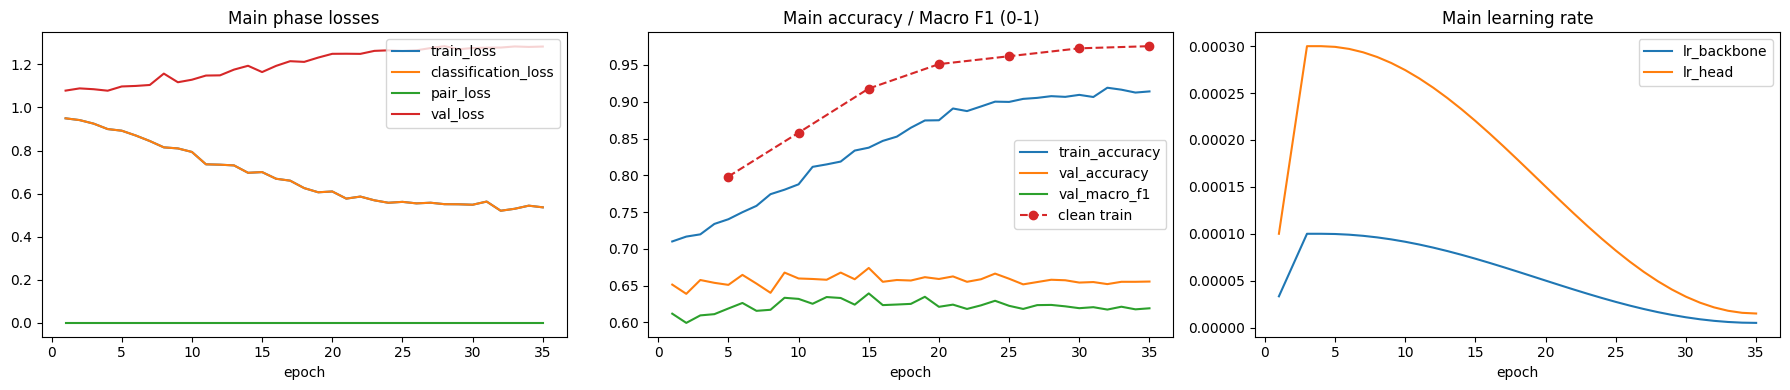

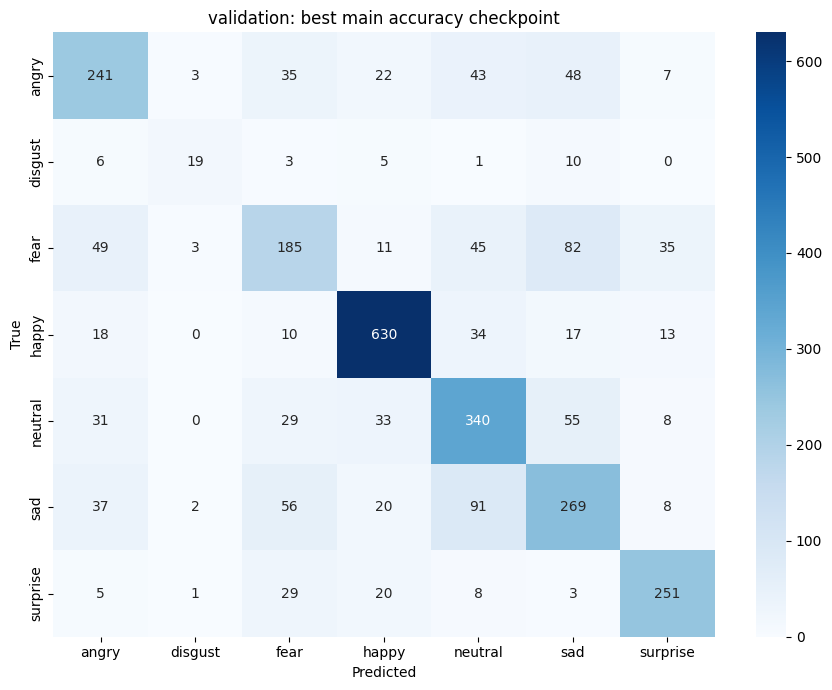

validation {
  "loss": 1.1644372484983778,
  "accuracy": 0.6739811912225705,
  "macro_f1": 0.6393870446304677,
  "balanced_accuracy": 0.6276916703414178,
  "global_accuracy": 0.6739811912225705,
  "changed_predictions": 0,
  "helpful_corrections": 0,
  "harmful_corrections": 0,
  "sample_count": 2871,
  "mean_gates": []
}
              precision    recall  f1-score   support

       angry     0.6227    0.6040    0.6132       399
     disgust     0.6786    0.4318    0.5278        44
        fear     0.5331    0.4512    0.4888       410
       happy     0.8502    0.8726    0.8612       722
     neutral     0.6050    0.6855    0.6427       496
         sad     0.5558    0.5569    0.5564       483
    surprise     0.7795    0.7918    0.7856       317

    accuracy                         0.6740      2871
   macro avg     0.6607    0.6277    0.6394      2871
weighted avg     0.6710    0.6740    0.6711      2871



In [28]:
fig, axes = plt.subplots(1,3,figsize=(18,4))
history.plot(x='epoch', y=['train_loss','classification_loss','pair_loss','val_loss'], ax=axes[0], title='Main phase losses')
history.plot(x='epoch', y=['train_accuracy','val_accuracy','val_macro_f1'], ax=axes[1], title='Main accuracy / Macro F1 (0-1)')
clean = history.dropna(subset=['clean_train_accuracy'])
axes[1].plot(clean.epoch, clean.clean_train_accuracy, 'o--', label='clean train')
axes[1].legend()
history.plot(x='epoch', y=['lr_backbone','lr_head'], ax=axes[2], title='Main learning rate')
fig.tight_layout()
fig.savefig(RUN_DIR/'training_history.png', dpi=150)
plt.show()
validation_result = evaluate(model, loaders['val'], DEVICE, CFG, collect_pair_details=True)
validation_paths = split_manifest.loc[split_manifest['split']=='val','path'].tolist()
validation_metrics = export_report(validation_result, RUN_DIR, 'validation', PAIRS, validation_paths)

## 8. Test cuối — sau khi chốt cấu hình

Đặt `RUN_FINAL_TEST=False` trong lúc chọn preset bằng validation. Sau khi chốt,
bật True để Run All xuất report test. Cell nạp cấu hình và danh sách cặp từ run
đã lưu, không chọn cặp hay class weights dựa trên test.

Dataset này thường có 7.178 ảnh test; không so trực tiếp với benchmark dùng
riêng PrivateTest 3.589 ảnh. Test cũng đã được tham khảo trong quá trình phát
triển dự án, nên cần báo cáo điều này thay vì xem là bộ kiểm tra chưa từng dùng.

Reading 7,178 images with 8 continuous I/O threads.


Read/decode source images: 100%|██████████| 7178/7178 [00:49<00:00, 144.95img/s]


Cached 7,178/7,178 images | RGB 47.3 MiB | 49.5s
Reusable cache pack: /kaggle/working/.fer_image_cache/rgb-0765f237e760d6967703e4d67caa1becf2dcabe4c20d598f664b072633a4b054.npz


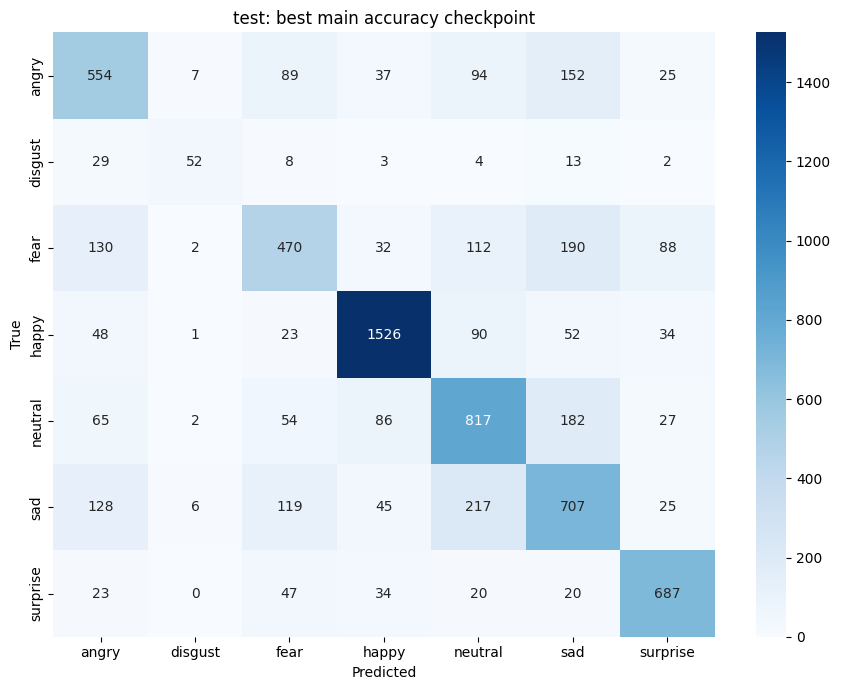

test {
  "loss": 1.1667113630975579,
  "accuracy": 0.6705210365004179,
  "macro_f1": 0.6436047543137269,
  "balanced_accuracy": 0.6317472712385602,
  "global_accuracy": 0.6705210365004179,
  "changed_predictions": 0,
  "helpful_corrections": 0,
  "harmful_corrections": 0,
  "sample_count": 7178,
  "mean_gates": []
}
              precision    recall  f1-score   support

       angry     0.5670    0.5783    0.5726       958
     disgust     0.7429    0.4685    0.5746       111
        fear     0.5802    0.4590    0.5125      1024
       happy     0.8656    0.8602    0.8629      1774
     neutral     0.6034    0.6626    0.6316      1233
         sad     0.5372    0.5670    0.5517      1247
    surprise     0.7736    0.8267    0.7993       831

    accuracy                         0.6705      7178
   macro avg     0.6671    0.6317    0.6436      7178
weighted avg     0.6704    0.6705    0.6686      7178

Test accuracy: 67.05% | Test Macro F1: 64.36%


In [31]:
def evaluate_final_test(run_dir, root, device):
    metadata = json.loads((Path(run_dir)/'training.json').read_text(encoding='utf-8'))
    cfg = metadata['config']
    restored = load_trained_model(Path(run_dir)/metadata['checkpoint_file'], device)
    restored = prepare_model(restored, cfg, device)
    dataset = datasets.ImageFolder(Path(root)/'test', transform=build_transforms(cfg))
    check_classes(dataset)
    attach_image_cache(cfg, dataset)
    loader = DataLoader(dataset, batch_size=cfg['batch_size'], shuffle=False,
                        num_workers=cfg['num_workers'], pin_memory=device.type=='cuda', worker_init_fn=seed_worker)
    result = evaluate(restored, loader, device, cfg, collect_pair_details=True)
    paths = [str(Path(p).relative_to(root)) for p,_ in dataset.samples]
    metrics = export_report(result, run_dir, 'test', metadata['model_config']['pairs'], paths)
    print(f'Test accuracy: {result["accuracy"]:.2%} | Test Macro F1: {result["macro_f1"]:.2%}')
    return result, metrics


RUN_FINAL_TEST = True
if RUN_FINAL_TEST:
    test_result, test_metrics = evaluate_final_test(RUN_DIR, DATA_ROOT, DEVICE)
else:
    print('Chưa đọc test; tiếp tục chọn cấu hình bằng validation.')

## 9. File nào cần tải?

Thư mục run hiện tại được in bởi `Output:`. Mỗi lần chạy cell tạo dữ liệu tạo
một thư mục mới, không tự resume. Các file quan trọng:

- **`pair_correction_best_checkpoint.pth`**: nên tải; weights + kiến trúc,
  cặp, nhãn, tiền xử lý và best main epoch. Nạp được trên một GPU hoặc CPU.
- `pair_correction_best.pth`: raw state dict; phải có cùng kiến trúc/cặp.
- `pilot_global_best_checkpoint.pth`, `pilot_history.csv`: chi phí và kết quả pilot.
- `pairs.json`, `pilot_pair_ranking.csv`: cặp được chọn và nguồn chọn cặp.
- `pilot_validation_snapshots.json`, `pilot_pair_stability.csv`,
  `pilot_mining_confusion_mean.csv`: confusion qua epoch và độ ổn định chọn cặp.
- `training.json`, `model_config.json`, `class_weights.csv`, `split_manifest.csv`.
- `main_history.csv`, report, confusion matrix, predictions có gate/delta,
  `*_pair_diagnostics.csv` và `*_pair_by_class.csv`.

Sau khi chạy cell định nghĩa model:

```python
restored = load_trained_model(RUN_DIR/'pair_correction_best_checkpoint.pth', DEVICE)
with torch.inference_mode():
    logits = restored(tensor)['logits']  # tensor B×3×H×H, H khớp checkpoint (mặc định 112)
```

Không dùng weights này trực tiếp với ứng dụng CCT/CNN cũ. Checkpoint không
lưu optimizer để resume train và không đại diện weights của batch đang chạy.
Kết quả chỉ là best main validation checkpoint; best pilot được lưu riêng.

**Cách đối chứng:** chạy `global_ce`, `pair_ce`, `global_balanced`, `pair_balanced`
cùng split/pilot/seed và ngân sách. Nếu nhánh có lợi, so thêm `pair_no_gate`
và `pair_random`. Thử nhiều seed train, giữ mining_seed/split_seed để giữ
cùng pilot/cặp/split. Pretraining ImageNet có thể giúp hoặc không; so random
initialization trong thí nghiệm riêng nếu cần xác định đóng góp pretrain.

Nguồn thành phần: [MobileNetV3](https://arxiv.org/abs/1905.02244),
[Class-Balanced Loss](https://arxiv.org/abs/1901.05555).
Các ý tưởng specialist/pairwise có tiền lệ; notebook không xác nhận tính mới
học thuật hoặc bảo đảm accuracy. Báo cáo cả chi phí pilot, inference latency
đo thực tế và Macro F1, không chỉ số tham số.

Mặc định global_ce_224, RUN_FINAL_TEST=False. Run mới chưa có accuracy được đo;
đánh giá baseline rồi mới bật nhánh/loss. Nạp checkpoint cũ mặc định linear/112; checkpoint mới lưu head_type và image_size,
cần tạo đúng classifier và resize đúng khi inference. Thanh tiến độ text
(tqdm thông thường) không cần Jupyter widget.